[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vzavala/PCML_PEQ_2026/blob/main/JupyterNotebooks/PCML_Module3_Bayes_LinearModel.ipynb)

# Module 3 Tutorial: Bayesian Estimation for a Linear Model
## Physics-Constrained Machine Learning: Concepts, Tools, and Algorithms

**Victor M. Zavala and Angan Mukherjee — University of Wisconsin-Madison**

Adapted from the notebook `ch5_bayes_estimation` of *Statistics for Chemical Engineers* (V. M. Zavala, Cambridge
University Press, 2025). In this tutorial, we will:

1. Build the prior, likelihood, and posterior of a linear model $Y=\theta X+\epsilon$ with a single observation
   $(x=1,y=2)$ and prior $\theta\sim\mathcal N(0,1)$.
2. Visualize how the posterior blends prior knowledge and data.

### Connection to the slides (Module 3)

| Slides | Code |
|---|---|
| Parameter $\theta$ | `th` (grid of values) |
| Prior $f(\theta)$, $\mathcal N(\bar\theta,\sigma_\theta^2)$ | `logpth`, `th0`, `sig0` |
| Likelihood $f(y\mid\theta)$ | `logpyth`, `sig` |
| Posterior $f(\theta\mid y)\propto f(y\mid\theta)f(\theta)$ | `logpthy` |

### Before the workshop

Runs locally or on Google Colab with NumPy and Matplotlib.

In [1]:
# Victor Z, Jaron T
# UW-Madison, 2024
# bayes estimation example

In [2]:
import numpy as np
import matplotlib.pyplot as plt

### 1. Prior, likelihood, and posterior

In [3]:
# span theta values
th = np.linspace(-3, 3, 100)

# construct prior function p(th)
sig0 = 1
th0 = 0
logpth = -np.log(np.sqrt(2 * np.pi * sig0**2)) - ((th - th0)**2) / (2 * sig0)

# construct p(y|th)
sig = 1
y = 2
x = 1

logpyth = -np.log(np.sqrt(2 * np.pi * sig**2)) - ((y - th * x)**2) / (2 * sig)

# construct p(th|y)
logpthy = logpyth + logpth


### 2. Visualize prior, likelihood, and posterior

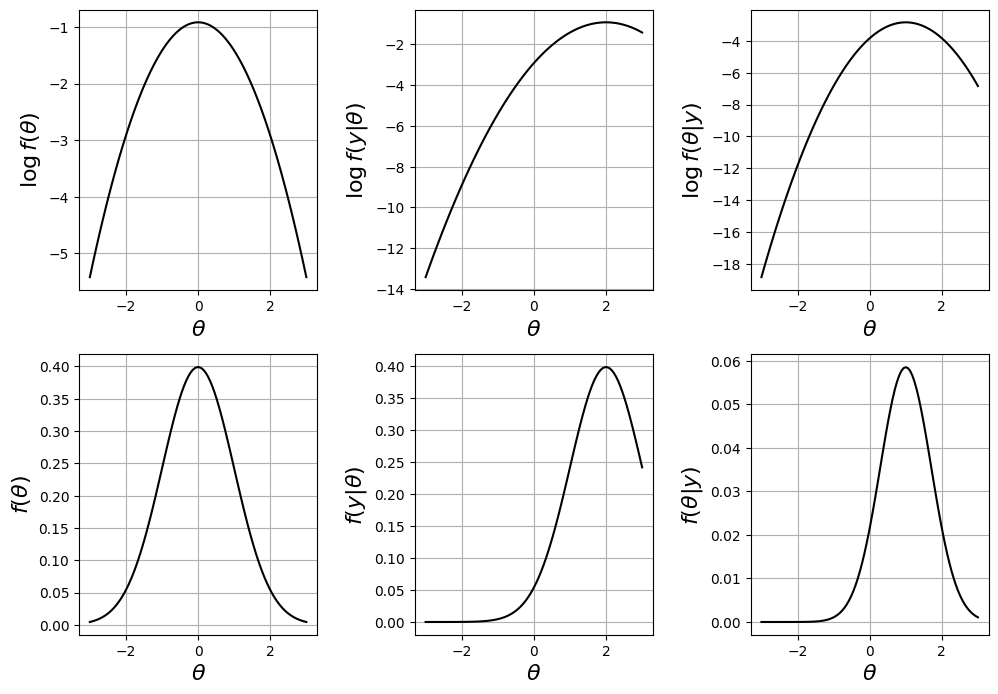

In [4]:
# visualize prior and conditional in log space
plt.figure(1, figsize=(10, 10))
plt.subplot(3, 3, 1)
plt.plot(th, logpth, 'k', linewidth=1.5)
plt.xlabel(r'$\theta$', fontsize=16)
plt.ylabel(r'$\log f(\theta)$', fontsize=16)
plt.grid(True)

plt.subplot(3, 3, 2)
plt.plot(th, logpyth, 'k', linewidth=1.5)
plt.xlabel(r'$\theta$', fontsize=16)
plt.ylabel(r'$\log f(y|\theta)$', fontsize=16)
plt.grid(True)

plt.subplot(3, 3, 3)
plt.plot(th, logpthy, 'k', linewidth=1.5)
plt.xlabel(r'$\theta$', fontsize=16)
plt.ylabel(r'$\log f(\theta|y)$', fontsize=16)
plt.grid(True)

# visualize in original space
plt.subplot(3, 3, 4)
plt.plot(th, np.exp(logpth), 'k', linewidth=1.5)
plt.xlabel(r'$\theta$', fontsize=16)
plt.ylabel(r'$f(\theta)$', fontsize=16)
plt.grid(True)

plt.subplot(3, 3, 5)
plt.plot(th, np.exp(logpyth), 'k', linewidth=1.5)
plt.xlabel(r'$\theta$', fontsize=16)
plt.ylabel(r'$f(y|\theta)$', fontsize=16)
plt.grid(True)

plt.subplot(3, 3, 6)
plt.plot(th, np.exp(logpthy), 'k', linewidth=1.5)
plt.xlabel(r'$\theta$', fontsize=16)
plt.ylabel(r'$f(\theta|y)$', fontsize=16)
plt.grid(True)

plt.tight_layout()
plt.show()


### 3. Key takeaways

- The prior says $\theta=0$ is most likely; the data (MLE) say $\theta=2$; the posterior blends both and gives $\theta=1$.
- The prior acts as a regularizer: maximizing the posterior (MAP) is the same as minimizing the data loss plus a penalty.
- This is the same mechanism that regularizes NNs and physics-informed ML models (Modules 1-3).

### References

- Zavala, V. M. (2025). *Statistics for Chemical Engineers*. Cambridge University Press. https://doi.org/10.1017/9781009541916